# 4 — Across resolutions

The deviation network is fully convolutional, so a model trained at one
resolution can be applied at another one without retraining. Here the model
trained at $128\times128$ is evaluated on the same held-out Mayo slice at
$128\times128$ (the training resolution) and at its native resolution
$512\times512$. Run `main.py` first.

Figures and the table are saved in `plots/` (prefix `4_`).

In [9]:
import numpy as np
import torch

from utils.experiments import (build_test_instance, reference_solution, run_fbs,
                               objective_gap, load_model)
from utils.plots import apply_paper_style, plot_curves, show_images

apply_paper_style()

In [10]:
# --- configuration (must match main.py) ---------------------------------------
EVAL_SIZE = 512              # one fixed resolution for comparing checkpoints
TRAIN_SIZES = [128, 512]    # training resolutions of the learned networks
N_ANGLES = 180
NOISE_LEVEL = 0.05
GAMMA = 2
PRIMAL_STEP = 1            # primal step tau (see main.py)

TEST_PATIENT = "L014"      # never used for training or validation
TEST_SLICE = 0
MAYO_CACHE_DIR = "./data/mayo_cache_{}"                # one cache per resolution

T_TRAIN = 10               # unrolling horizon used in training
T_LONG = 100               # length of the convergence curves
T_REF = 6000               # length of the run that defines F* (cached in results/)

## Runs

The same weights are loaded at every resolution: only the operators change.

In [ ]:
results, refs, instances = {}, {}, {}
for size in [EVAL_SIZE]:
    inst = build_test_instance(size, N_ANGLES, NOISE_LEVEL, GAMMA, TEST_PATIENT, TEST_SLICE,
                               MAYO_CACHE_DIR.format(size), primal_step=PRIMAL_STEP)
    ref = reference_solution(inst, T_REF)
    print(f"{size}x{size}: F* = {ref['f_star']:.4f}, "
          f"PSNR of the TGV2 solution = {ref['psnr']:.2f} dB")
    results[size] = {
        "Zero deviation": run_fbs(inst, T_LONG, snapshots=(T_TRAIN,)),
    }
    for train_size in TRAIN_SIZES:
        model, _ = load_model(f"model_{train_size}.pt", inst, T=T_TRAIN)
        results[size][f"Learned ({train_size} training)"] = run_fbs(
            inst, T_LONG, model, snapshots=(T_TRAIN,))
    refs[size], instances[size] = ref, inst

/home/beille/venv/lib/python3.12/site-packages/odl/tomo/backends/astra_cpu.py:318: RuntimeWarning: The 'astra_cpu' backend may be too slow for volumes of this size. Consider using 'astra_cuda' if your machine has an Nvidia GPU.
  warnings.warn(


512x512: F* = 8.0576, PSNR of the TGV2 solution = 26.41 dB


 89%|████████▉ | 89/100 [01:33<00:11,  1.07s/it] 

## Convergence at each resolution

128x128


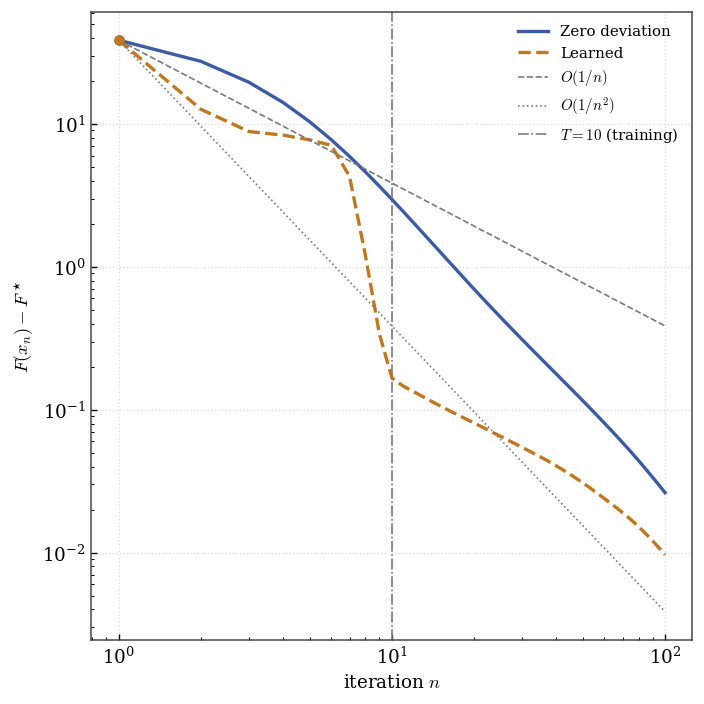

512x512


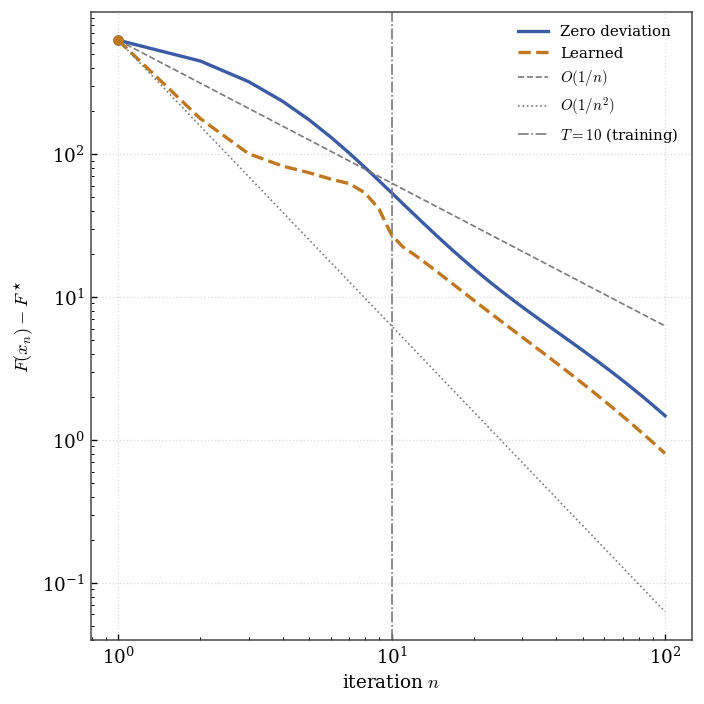

In [ ]:
gaps = {size: {label: objective_gap(r, refs[size]["f_star"]) for label, r in results[size].items()}
        for size in [EVAL_SIZE]}
for size in [EVAL_SIZE]:
    print(f"{size}x{size}")
    plot_curves(gaps[size], r"$F(x_n) - F^\star$", f"4_objective_gap_{size}", slopes=True,
                horizon=T_TRAIN, iteration_start=0, show=True)

## Gain across resolutions

Objective gap of the learned scheme divided by the gap of the zero-deviation
baseline at the same iteration. Below 1, the learned scheme is ahead.

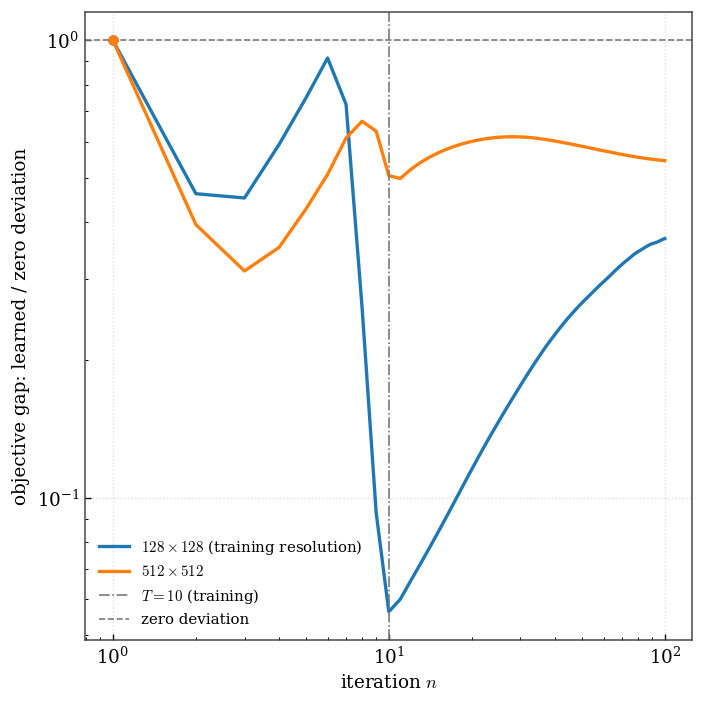

In [ ]:
ratios = {f"{label} at {size}x{size}": gaps[size][label][T_TRAIN] / gaps[size]["Zero deviation"][T_TRAIN]
          for size in [EVAL_SIZE] for label in results[size] if label != "Zero deviation"}
plot_curves(ratios, "objective gap: learned / zero deviation", "4_gap_ratio",
            horizon=T_TRAIN, hline=(1.0, "zero deviation"), iteration_start=0, show=True)

## PSNR

128x128


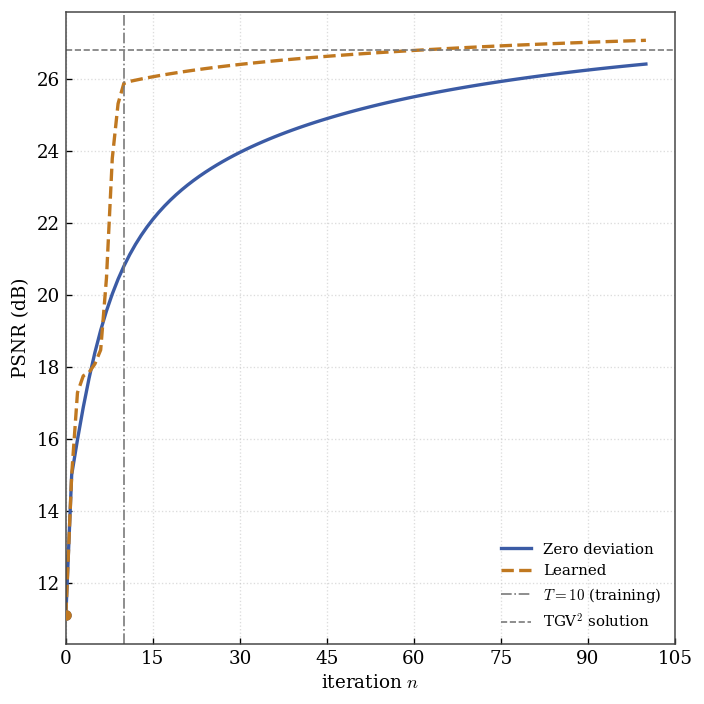

512x512


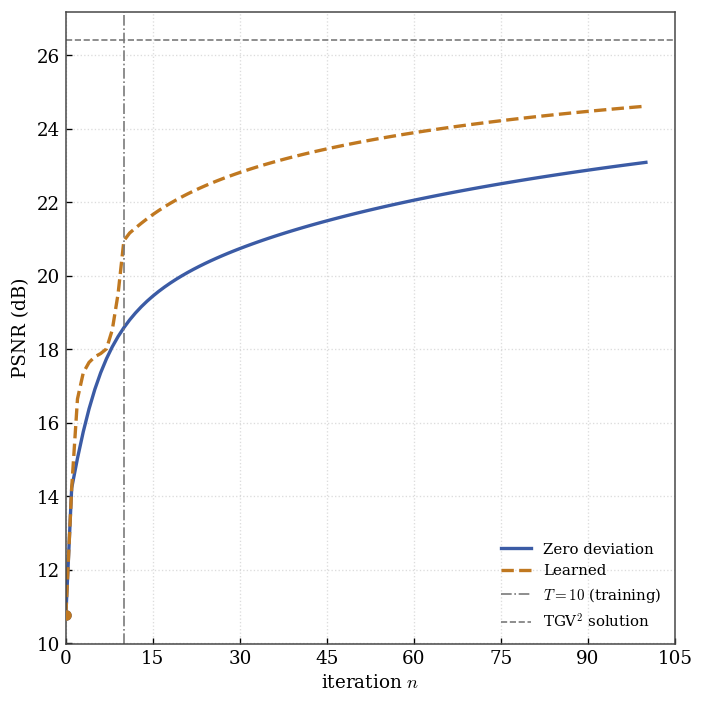

In [ ]:
for size in [EVAL_SIZE]:
    print(f"{size}x{size}")
    plot_curves({label: r["psnr"] for label, r in results[size].items()}, "PSNR (dB)",
                f"4_psnr_{size}", loglog=False, horizon=T_TRAIN,
                hline=(refs[size]["psnr"], r"TGV$^2$ solution"), iteration_start=0, show=True)

## Reconstructions

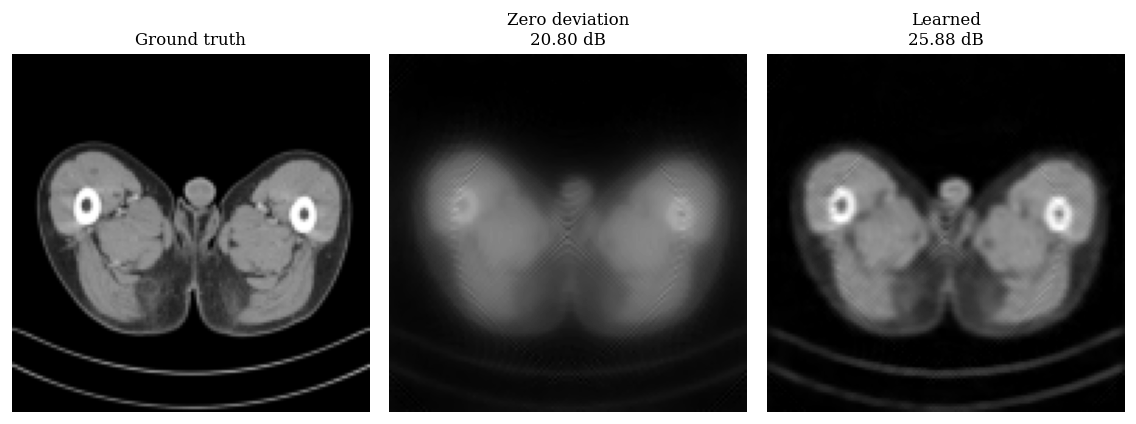

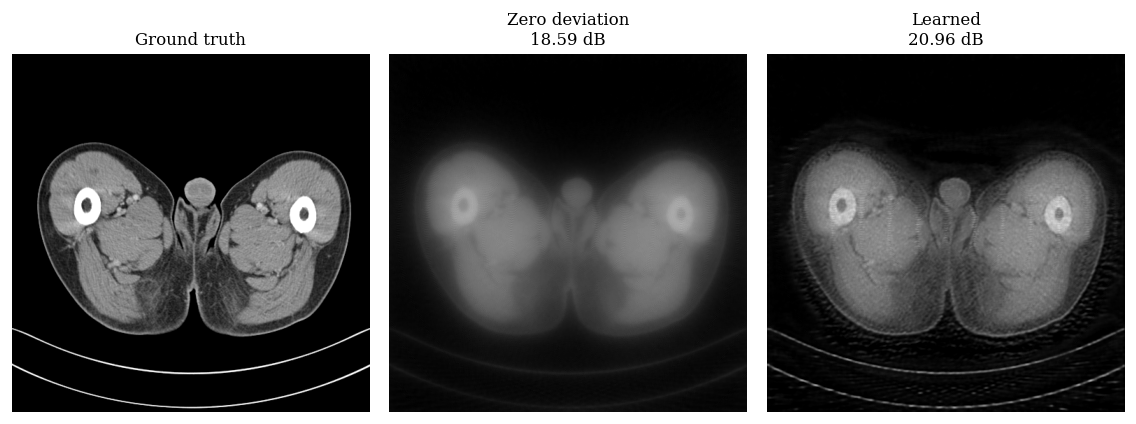

In [ ]:
def gallery(size, n):
    """Ground truth and the reconstruction of every method after n iterations."""
    images = {"Ground truth": instances[size]["clean"]}
    for label, r in results[size].items():
        images[f"{label}\n{r['psnr'][n]:.2f} dB"] = r["images"][n]
    return images

for size in [EVAL_SIZE]:
    show_images(gallery(size, T_TRAIN), f"4_reconstructions_{size}_{T_TRAIN}_iterations", show=True)

## Summary

Objective gap and PSNR after 10, 20 and 100 iterations, and the first
iteration from which the learned scheme stays ahead of the baseline. The table
is also written as LaTeX in `plots/`.

In [ ]:
import os
import pandas as pd

rows = []
for size in [EVAL_SIZE]:
    baseline = gaps[size]["Zero deviation"]
    for label, r in results[size].items():
        row = {"Resolution": f"{size}x{size}", "Method": label}
        for n in (10, 20, 100):
            row[f"F-F*, {n} it."] = f"{gaps[size][label][n]:.3g}"
            row[f"PSNR, {n} it. (dB)"] = f"{r['psnr'][n]:.2f}"
        row["Time / iteration (ms)"] = f"{r['ms_per_iter']:.0f}"
        if label == "Zero deviation":
            row["Ahead from iteration"] = ""
        else:
            ahead = gaps[size][label] < baseline
            behind = np.flatnonzero(~ahead)
            row["Ahead from iteration"] = int(behind[-1]) + 1 if len(behind) else 0
        rows.append(row)
table = pd.DataFrame(rows).set_index(["Resolution", "Method"])

os.makedirs("plots", exist_ok=True)
with open(os.path.join("plots", "4_resolution_comparison.tex"), "w") as file:
    file.write(table.to_latex(escape=True))
table

F-F*, 10 it. PSNR, 10 it. (dB) F-F*, 20 it.  \
Resolution Method                                                       
128x128    Zero deviation         2.96             20.80        0.698   
           Learned               0.167             25.88       0.0806   
512x512    Zero deviation         53.6             18.59         15.8   
           Learned                27.1             20.96         9.47   

                          PSNR, 20 it. (dB) F-F*, 100 it. PSNR, 100 it. (dB)  \
Resolution Method                                                              
128x128    Zero deviation             22.92        0.0262              26.41   
           Learned                    26.19       0.00966              27.07   
512x512    Zero deviation             20.00          1.47              23.09   
           Learned                    22.15         0.803              24.62   

                          Time / iteration (ms) Ahead from iteration  
Resolution Method                                                     
128x128    Zero deviation                    57                       
           Learned                          142                    2  
512x512    Zero deviation                   584                       
           Learned                          857                    2

## Gradient flow

The second primal block is the TGV auxiliary field `w`, not the image gradient. The dashed streamlines below show the spatial gradient `grad(u)` of each reconstruction.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

size = EVAL_SIZE
iteration = T_TRAIN
methods = list(results[size])
fig, axes = plt.subplots(1, len(methods), figsize=(5.2 * len(methods), 4.8), squeeze=False)

for ax, label in zip(axes[0], methods):
    u = results[size][label]["images"][iteration].to(instances[size]["device"])
    gradient = instances[size]["functions"]["grad"](u)[0].detach().cpu().numpy()
    image = u[0, 0].detach().cpu().numpy()
    gy, gx = gradient[0], gradient[1]
    step = 8
    y, x = np.mgrid[0:size:step, 0:size:step]
    speed = np.hypot(gx, gy)
    ax.imshow(image, cmap="gray", origin="upper")
    flow = ax.streamplot(x[0], y[:, 0], gx[::step, ::step], -gy[::step, ::step],
                         color="tab:red", density=1.0, linewidth=0.7,
                         arrowsize=0.7, minlength=0.1, broken_streamlines=False)
    flow.lines.set_linestyle((0, (4, 3)))
    ax.set_title(f"{label}\n$\\|\\nabla u\\|$ mean = {speed.mean():.3g}")
    ax.set_xlim(0, size - 1)
    ax.set_ylim(size - 1, 0)
    ax.set_axis_off()

plt.tight_layout()
plt.savefig("plots/4_gradient_flow_512.png", dpi=200, bbox_inches="tight")
plt.show()